# Lab Assignment 8 — NLP and Topic Modelling of Healthcare Headlines

## 1. Install and import libraries
Run the installation cell once in a fresh environment. Restart the kernel if the notebook asks you to.

In [1]:
%pip install -q pandas numpy matplotlib seaborn nltk wordcloud scikit-learn gensim pyLDAvis requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import json
import glob
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 2. Dataset configuration and loading
The repository may contain multiple files or formats. The code below lists candidate CSV/JSON files, downloads them, and selects the first usable tabular dataset. If the repository layout changes, inspect the candidate list and set `DATASET_URL` manually.

In [3]:
REPOSITORY_API = (
    "https://api.github.com/repos/WuraolaOyewusi/"
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing/contents"
)
# Exact repository slug from the assignment PDF (GitHub URLs may redirect/normalize it).
REPOSITORY_PAGE = "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing"

# Optional: set this to a local CSV/JSON path if you downloaded the data manually.
LOCAL_DATA_PATH = None

# Optional: set a direct raw CSV/JSON URL to bypass automatic discovery.
DATASET_URL = (
    "https://raw.githubusercontent.com/WuraolaOyewusi/"
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing/"
    "master/Health_Related_Headlines_Dataset.csv"
)

def github_file_candidates(api_url):
    response = requests.get(api_url, timeout=30)
    response.raise_for_status()
    items = response.json()
    candidates = []
    for item in items:
        if item.get("type") == "file" and item.get("name", "").lower().endswith((".csv", ".json")):
            candidates.append({"name": item["name"], "download_url": item.get("download_url")})
        elif item.get("type") == "dir":
            # Inspect one directory level for data files.
            sub = requests.get(item["url"], timeout=30)
            if sub.ok:
                for child in sub.json():
                    if child.get("type") == "file" and child.get("name", "").lower().endswith((".csv", ".json")):
                        candidates.append({"name": child["name"], "download_url": child.get("download_url")})
    return candidates

def read_dataset_from_url(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    if url.lower().split("?")[0].endswith(".json"):
        try:
            return pd.read_json(response.text)
        except ValueError:
            data = [json.loads(line) for line in response.text.splitlines() if line.strip()]
            return pd.DataFrame(data)
    # CSV
    from io import StringIO
    return pd.read_csv(StringIO(response.text), on_bad_lines="skip")

df = None
source_description = None

if LOCAL_DATA_PATH:
    local_path = Path(LOCAL_DATA_PATH).expanduser()
    if not local_path.exists():
        raise FileNotFoundError(f"LOCAL_DATA_PATH does not exist: {local_path}")
    if local_path.suffix.lower() == ".json":
        try:
            df = pd.read_json(local_path)
        except ValueError:
            df = pd.read_json(local_path, lines=True)
    else:
        df = pd.read_csv(local_path, on_bad_lines="skip")
    source_description = str(local_path)

elif DATASET_URL:
    df = read_dataset_from_url(DATASET_URL)
    source_description = DATASET_URL

else:
    try:
        candidates = github_file_candidates(REPOSITORY_API)
        print("CSV/JSON candidates found:")
        display(pd.DataFrame(candidates))
        if not candidates:
            raise RuntimeError("No CSV/JSON files found through the GitHub repository API.")
        last_error = None
        for candidate in candidates:
            try:
                candidate_df = read_dataset_from_url(candidate["download_url"])
                if not candidate_df.empty:
                    df = candidate_df
                    source_description = candidate["download_url"]
                    break
            except Exception as exc:
                last_error = exc
        if df is None:
            raise RuntimeError(f"Could not load any candidate file. Last error: {last_error}")
    except Exception as exc:
        print("Automatic GitHub loading failed:", repr(exc))
        print("Download a CSV/JSON file from the repository, then set LOCAL_DATA_PATH above and rerun this cell.")
        raise

print("Loaded from:", source_description)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("data_type"))

Loaded from: https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Health_Related_Headlines_Dataset.csv
Dataset shape: (39405, 5)


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Recommendations,New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what you need to know.,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention May Facilitate Smoking Cessation,"In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed static and dynamic Internet interventions.",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood Mood Disorders,It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoholism.,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Dependence,The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on Patients With Chronic Low...,"A small study using one variety of magnet for treatment of low back pain had no effect on patients' pain; however, the researchers say that additional studies are needed to ver...",Pain Management


,data_type
Date,object
Source,object
Headlines,object
Teaser,object
Category,object


## 3. Identify and combine text fields

The assignment describes headlines, titles and teasers. This cell looks for columns with those names (case-insensitive). If your copy uses different column names, edit `TEXT_COLUMNS` manually after inspecting `df.columns`.

In [4]:
print("Available columns:")
print(df.columns.tolist())

TEXT_KEYWORDS = ("headline", "title", "teaser", "description", "summary", "text", "article")
TEXT_COLUMNS = [
    col for col in df.columns
    if any(keyword in str(col).lower() for keyword in TEXT_KEYWORDS)
]

# Avoid accidentally including metadata columns such as title_url or article_id.
TEXT_COLUMNS = [
    col for col in TEXT_COLUMNS
    if not any(token in str(col).lower() for token in ("url", "link", "id", "date", "author", "source"))
]

print("Detected text columns:", TEXT_COLUMNS)

if not TEXT_COLUMNS:
    # Fallback: columns with string/object values and meaningful text length.
    object_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
    TEXT_COLUMNS = [
        col for col in object_cols
        if df[col].dropna().astype(str).str.len().median() > 15
    ]
    print("Fallback text columns:", TEXT_COLUMNS)

if not TEXT_COLUMNS:
    raise ValueError("No text columns detected. Set TEXT_COLUMNS manually based on df.columns.")

df["raw_text"] = (
    df[TEXT_COLUMNS]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)
df = df[df["raw_text"].str.len() > 0].copy()
df.reset_index(drop=True, inplace=True)

print("Rows with usable text:", len(df))
display(df[TEXT_COLUMNS + ["raw_text"]].head(5))

Available columns:
['Date', 'Source', 'Headlines', 'Teaser', 'Category']
Detected text columns: ['Headlines', 'Teaser']
Rows with usable text: 39405


,Headlines,Teaser,raw_text
0,Special Report: Adult Vaccines -- New ACIP Recommendations,New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what you need to know.,Special Report: Adult Vaccines -- New ACIP Recommendations New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what...
1,Combined Internet and Telephone Intervention May Facilitate Smoking Cessation,"In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed static and dynamic Internet interventions.","Combined Internet and Telephone Intervention May Facilitate Smoking Cessation In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed..."
2,Link Between Parental Alcoholism and Childhood Mood Disorders,It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoholism.,Link Between Parental Alcoholism and Childhood Mood Disorders It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoh...
3,Methadone Dose in the Treatment of Opiate Dependence,The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.,Methadone Dose in the Treatment of Opiate Dependence The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.
4,Magnet Treatment Had No Beneficial Effect on Patients With Chronic Low...,"A small study using one variety of magnet for treatment of low back pain had no effect on patients' pain; however, the researchers say that additional studies are needed to ver...",Magnet Treatment Had No Beneficial Effect on Patients With Chronic Low... A small study using one variety of magnet for treatment of low back pain had no effect on patients' pa...


## Task 1 — Data preprocessing and cleaning

In [5]:
import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Could not download {resource}: {exc}")

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize

stop_words = set(stopwords.words("english"))
# Add a few generic terms that are often uninformative in news-headline corpora.
stop_words.update({"said", "says", "new", "one", "two", "year", "years", "may", "also"})
lemmatizer = WordNetLemmatizer()

def clean_and_tokenize(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)  # punctuation and digits
    text = re.sub(r"\s+", " ", text).strip()
    tokens = wordpunct_tokenize(text)
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if len(token) > 2 and token not in stop_words and token.isalpha()
    ]
    return tokens

df["tokens"] = df["raw_text"].apply(clean_and_tokenize)
df["cleaned_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))
df = df[df["tokens"].map(len) > 0].copy()
df.reset_index(drop=True, inplace=True)

print("Cleaned samples:")
display(df[["raw_text", "cleaned_text"]].head(5))
print(f"Documents retained after cleaning: {len(df):,}")

Cleaned samples:


,raw_text,cleaned_text
0,Special Report: Adult Vaccines -- New ACIP Recommendations New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what...,special report adult vaccine acip recommendation recommendation already approved vaccine newly approved vaccine meningococcal infection need know
1,"Combined Internet and Telephone Intervention May Facilitate Smoking Cessation In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed...",combined internet telephone intervention facilitate smoking cessation randomized trial combined internet telephone treatment smoking cessation outperformed static dynamic inter...
2,Link Between Parental Alcoholism and Childhood Mood Disorders It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoh...,link parental alcoholism childhood mood disorder proposed depressed child identify family specific form bipolar disorder similar alcoholism
3,Methadone Dose in the Treatment of Opiate Dependence The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.,methadone dose treatment opiate dependence epidemic heroin abuse within produced influx addict requiring effective opioid substitution
4,Magnet Treatment Had No Beneficial Effect on Patients With Chronic Low... A small study using one variety of magnet for treatment of low back pain had no effect on patients' pa...,magnet treatment beneficial effect patient chronic low small study using variety magnet treatment low back pain effect patient pain however researcher say additional study need...


Documents retained after cleaning: 39,405


## Task 2 — Exploratory text analysis and word visualisation
### 2.1 Word frequency distribution

In [6]:
all_tokens = [token for tokens in df["tokens"] for token in tokens]
word_counts = Counter(all_tokens)
frequency_df = pd.DataFrame(word_counts.most_common(), columns=["word", "frequency"])

print("Unique words:", len(word_counts))
display(frequency_df.head(20))

Unique words: 24605


,word,frequency
0,patient,12973
1,risk,7630
2,study,6930
3,drug,6566
4,treatment,5779
5,cancer,5628
6,pain,5613
7,use,4993
8,disease,4114
9,vaccine,3499


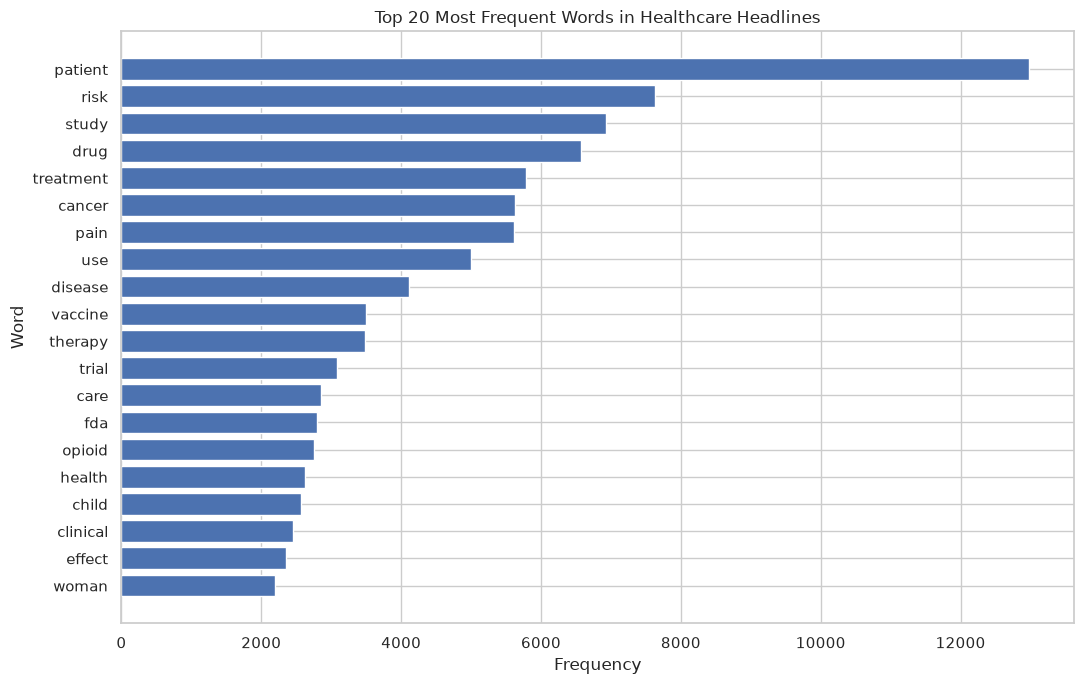

In [7]:
top_n = 20
top_words = frequency_df.head(top_n).sort_values("frequency", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(top_words["word"], top_words["frequency"])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 20 Most Frequent Words in Healthcare Headlines")
plt.tight_layout()
plt.show()

### 2.2 Word cloud

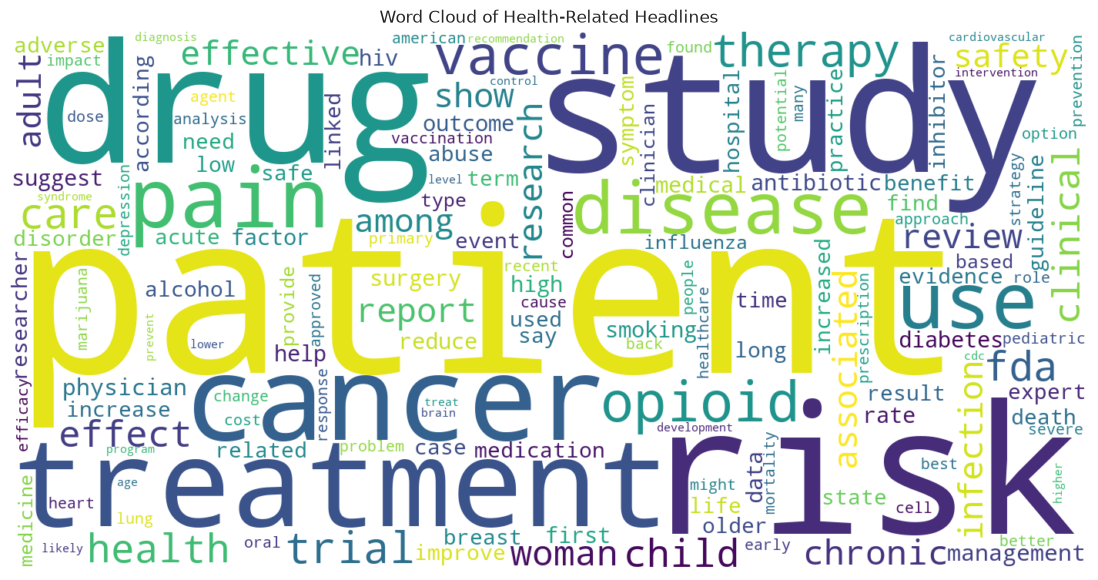

In [8]:
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    colormap="viridis",
    max_words=150,
    collocations=False
).generate(" ".join(all_tokens))

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Headlines")
plt.show()

## Task 3 — Topic modelling using LDA

LDA discovers groups of words that tend to occur together across documents. Each topic is represented by its highest-weight words. The number of topics is a modelling choice; this notebook starts with five topics, as requested for the topic-word display.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS = 5
N_TOP_WORDS = 5

# A document-term matrix is required by the LDA implementation.
vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2,
    max_features=5000,
    stop_words="english"
)
dtm = vectorizer.fit_transform(df["cleaned_text"])
feature_names = vectorizer.get_feature_names_out()

print("Document-term matrix shape:", dtm.shape)
if dtm.shape[1] == 0:
    raise ValueError("The document-term matrix is empty. Check the text columns and preprocessing settings.")

lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    learning_method="batch",
    max_iter=20
)
document_topic_matrix = lda.fit_transform(dtm)

def display_topics(model, feature_names, n_top_words=5):
    rows = []
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[:-n_top_words - 1:-1]
        words = [feature_names[i] for i in top_indices]
        rows.append({"Topic": f"Topic {topic_idx + 1}", "Top words": ", ".join(words)})
    return pd.DataFrame(rows)

topic_summary = display_topics(lda, feature_names, N_TOP_WORDS)
display(topic_summary)

Document-term matrix shape: (39405, 5000)


,Topic,Top words
0,Topic 1,"cancer, risk, patient, study, trial"
1,Topic 2,"pain, patient, treatment, therapy, chronic"
2,Topic 3,"vaccine, infection, hiv, child, antibiotic"
3,Topic 4,"drug, fda, patient, opioid, physician"
4,Topic 5,"study, use, disease, risk, disorder"


### 3.1 Assign the dominant topic to each headline

,Topic,Number of documents
0,1,8896
1,2,9168
2,3,5813
3,4,9152
4,5,6376


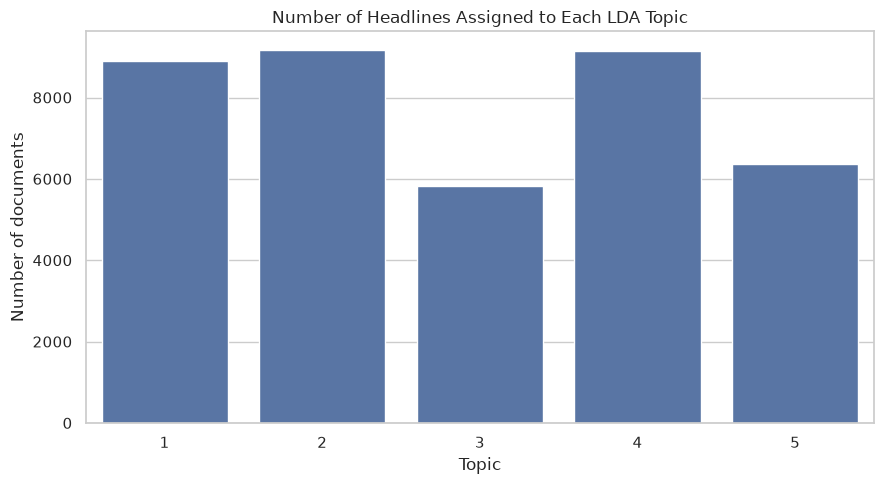

,raw_text,dominant_topic,topic_probability
0,Special Report: Adult Vaccines -- New ACIP Recommendations New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what...,3,0.952233
1,"Combined Internet and Telephone Intervention May Facilitate Smoking Cessation In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed...",1,0.780678
2,Link Between Parental Alcoholism and Childhood Mood Disorders It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoh...,5,0.954702
3,Methadone Dose in the Treatment of Opiate Dependence The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.,2,0.558312
4,Magnet Treatment Had No Beneficial Effect on Patients With Chronic Low... A small study using one variety of magnet for treatment of low back pain had no effect on patients' pa...,2,0.675103
5,Ask the Experts - Investigational Agents for Mesothelioma? Update of important ongoing and completed clinical trials in heart failure patients.,1,0.574134
6,"Estrogen Replacement May Negate the Benefits of Growth Hormone In a preliminary study, researchers have found evidence that boosting production of growth hormone can reduce bod...",1,0.391065
7,MEDLINE Abstracts: Thalidomide Clinical Trials A regularly updated reference resource summarizing dosing and resistance data on investigational agents.,3,0.662641
8,"IRB/FDA Requirements Relevant to HIV/AIDS Clinical Trials During the past few years, a number of abuses have been committed in clinical trials.",4,0.750474
9,"HIV Clinical Trials in Correctional Settings: Right or Retrogression? Explore the advancements in clinical trial methodology, their utility in establishing treatment guidelines...",2,0.402167


In [10]:
df["dominant_topic"] = document_topic_matrix.argmax(axis=1) + 1
df["topic_probability"] = document_topic_matrix.max(axis=1)

topic_counts = (
    df["dominant_topic"]
    .value_counts()
    .sort_index()
    .rename_axis("Topic")
    .reset_index(name="Number of documents")
)
display(topic_counts)

plt.figure(figsize=(9, 5))
sns.barplot(data=topic_counts, x="Topic", y="Number of documents")
plt.title("Number of Headlines Assigned to Each LDA Topic")
plt.tight_layout()
plt.show()

display(df[["raw_text", "dominant_topic", "topic_probability"]].head(10))

### 3.2 Interactive topic visualisation with pyLDAvis

`pyLDAvis` displays the topic map and the most relevant terms for a selected topic. If the visualisation does not render in your notebook environment, the HTML file is saved locally and can be opened in a browser.

In [11]:
import pyLDAvis
import pyLDAvis.lda_model
from IPython.display import display

vis = pyLDAvis.lda_model.prepare(
    lda,
    dtm,
    vectorizer,
    mds="mmds",
    sort_topics=False
)

display(pyLDAvis.display(vis))

In [12]:
# Save an interactive HTML copy as well.
OUTPUT_HTML = "lab8_lda_visualization.html"
pyLDAvis.save_html(vis, OUTPUT_HTML)
print("Saved interactive LDA visualisation to:", os.path.abspath(OUTPUT_HTML))

Saved interactive LDA visualisation to: /run/media/sambhav/New Volume/Documents/UNI/4th year/Ai in Healthcare/ CSET343 Ai in  Healthcare/LAB 8/lab8_lda_visualization.html


## 4. Brief observations / conclusion

Use the outputs above to write your observations for submission:
1. **Preprocessing:** State how many records were loaded and how many remained after removing empty or unusable text.
2. **Frequent words:** Discuss the most frequent healthcare-related terms shown in the frequency table and bar chart.
3. **Word cloud:** Describe the prominent terms and how they reflect the dataset's health-news content.
4. **LDA topics:** For each of the five topics, interpret the five highest-weight words. Topic labels should be based on the words and example headlines, not guessed from the topic number alone.
5. **Limitations:** LDA is an unsupervised model; topics are approximate word co-occurrence patterns and are not verified medical conclusions.

### Optional: inspect example headlines per topic

In [13]:
print("df:", type(df), df is None)
print("document_topic_matrix:", type(document_topic_matrix))
print("Dataset variables available:")
print([x for x in globals() if x in ["df", "raw_text", "TEXT_COLUMNS", "dataset", "data"]])

df: <class 'pandas.core.frame.DataFrame'> False
document_topic_matrix: <class 'numpy.ndarray'>
Dataset variables available:
['df', 'TEXT_COLUMNS']


In [14]:
for topic_id in sorted(df["dominant_topic"].unique()):
    print(f"\\nTOPIC {topic_id}")
    examples = df.loc[df["dominant_topic"] == topic_id, "raw_text"].head(5)
    for i, example in enumerate(examples, start=1):
        print(f"{i}. {example}")

\nTOPIC 1
1. Combined Internet and Telephone Intervention May Facilitate Smoking Cessation In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed static and dynamic Internet interventions.
2. Ask the Experts - Investigational Agents for Mesothelioma? Update of important ongoing and completed clinical trials in heart failure patients.
3. Estrogen Replacement May Negate the Benefits of Growth Hormone In a preliminary study, researchers have found evidence that boosting production of growth hormone can reduce body fat and help maintain levels of functioning in elderly men and women.
4. Clinical Trials in ALS: An Overview Women's participation in clinical trials, particularly those involving drugs, has been said to be both overrepresented and underrepresented. Studies of participation are compared and contrasted to elucidate some reasons for this contradiction.
5. Urothelial Cancer: A Phase II Trial A study evaluates efficacy and toxicity in prev